# 01 · Discriminative predictive coding (Whittington & Bogacz style): MNIST classification

- PyTorch translation of the ngc-learn discriminative PC network (fully connected).


In [1]:
import torch
import torch.nn.functional as F
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from dataclasses import dataclass
import time

from archive.utils import get_device
DEVICE = get_device()
torch.manual_seed(1234)
print('Device:', DEVICE)


Device: mps


In [2]:
@dataclass
class Settings:
    hidden: int = 512
    output: int = 10
    steps: int = 20
    dt: float = 1.0
    tau_m: float = 25.0
    eta: float = 0.001
    batch_size: int = 250
    epochs: int = 100
    init_bound: float = 0.3
    target_epsilon: float = 0.001

cfg = Settings()
train_data = MNIST('data', train=True, download=True, transform=ToTensor())
test_data = MNIST('data', train=False, download=True, transform=ToTensor())
train_loader = DataLoader(train_data, batch_size=cfg.batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False, num_workers=0)
print('Train:', len(train_data), 'Test:', len(test_data))


Train: 60000 Test: 10000


In [3]:
class NGCLearnPCN:
    def __init__(self, cfg, device):
        self.cfg, self.device = cfg, device
        sizes = [784, cfg.hidden, cfg.hidden, cfg.output]
        self.weights = [torch.empty(sizes[i+1], sizes[i], device=device).uniform_(-cfg.init_bound, cfg.init_bound) for i in range(3)]
        self.biases = [torch.zeros(sizes[i+1], device=device) for i in range(3)]
        # Independent first and second Adam moments per weight/bias on each synaptic cable.
        self.m = [torch.zeros_like(p) for p in self.weights + self.biases]
        self.v = [torch.zeros_like(p) for p in self.weights + self.biases]
        self.t = [0, 0, 0]

    @torch.no_grad()
    def project(self, x):
        # Q1/Q2/Q3 tied to W1/W2/W3. RateCell state z is pre-activation.
        q1 = F.linear(x, self.weights[0], self.biases[0])
        q2 = F.linear(torch.sigmoid(q1), self.weights[1], self.biases[1])
        q3 = F.linear(torch.sigmoid(q2), self.weights[2], self.biases[2])
        return q1, q2, q3

    def bottom_up_prediction_error(self, x, z1, z2, y):
        mu1 = F.linear(x, self.weights[0], self.biases[0])
        mu2 = F.linear(torch.sigmoid(z1), self.weights[1], self.biases[1])
        mu3 = F.linear(torch.sigmoid(z2), self.weights[2], self.biases[2])
        return z1 - mu1, z2 - mu2, y - mu3  # dmu = target - prediction

    @torch.no_grad()
    def iterative_inference(self, x, labels):
        cfg = self.cfg
        y = F.one_hot(labels, cfg.output).to(x.dtype).clamp(cfg.target_epsilon, 1 - cfg.target_epsilon)
        z1, z2, raw_output = self.project(x)
        z1, z2 = z1.clone(), z2.clone()
        for _ in range(cfg.steps):
            e1, e2, e3 = self.bottom_up_prediction_error(x, z1, z2, y)
            # E2 = W2.T; E3 = W3.T; j is derivative-modulated, j_td is not.
            j1 = F.linear(e2, self.weights[1].T) * torch.sigmoid(z1) * (1 - torch.sigmoid(z1))
            j2 = F.linear(e3, self.weights[2].T) * torch.sigmoid(z2) * (1 - torch.sigmoid(z2))
            z1 = z1 + (cfg.dt / cfg.tau_m) * (j1 - e1)
            z2 = z2 + (cfg.dt / cfg.tau_m) * (j2 - e2)
        e1, e2, e3 = self.bottom_up_prediction_error(x, z1, z2, y)
        energy = 0.5 * (e1.square().sum() + e2.square().sum() + e3.square().sum())
        return (z1, z2), (e1, e2, e3), energy

    @torch.no_grad()
    def _adam_local(self, index, gradient_w, gradient_b):
        # Source Adam uses negative descent and sign_value=-1 on Hebbian terms.
        self.t[index] += 1
        parameters = [self.weights[index], self.biases[index]]
        gradients = [-gradient_w, -gradient_b]  # sign_value = -1
        for k, (p, g) in enumerate(zip(parameters, gradients)):
            i = index if k == 0 else index + 3
            self.m[i].mul_(0.9).add_(g, alpha=0.1)
            self.v[i].mul_(0.999).addcmul_(g, g, value=0.001)
            mhat = self.m[i] / (1 - 0.9 ** self.t[index])
            vhat = self.v[i] / (1 - 0.999 ** self.t[index])
            p.addcdiv_(mhat, vhat.sqrt() + 1e-8, value=-self.cfg.eta)

    @torch.no_grad()
    def train_batch(self, x, labels):
        (z1, z2), (e1, e2, e3), energy = self.iterative_inference(x, labels)
        local = [(x, e1), (torch.sigmoid(z1), e2), (torch.sigmoid(z2), e3)]
        for i, (pre, post) in enumerate(local):
            if not torch.isfinite(post).all(): raise FloatingPointError(f'Nonfinite local error at edge {i+1}')
            self._adam_local(i, post.T @ pre, post.sum(dim=0))
        return energy.item() / x.shape[0]

    @torch.no_grad()
    def predict(self, x):
        return self.project(x)[-1]


In [4]:
@torch.no_grad()
def evaluate(model, loader):
    total, correct, nll = 0, 0, 0.
    for images, labels in loader:
        x, y = images.to(DEVICE).flatten(1), labels.to(DEVICE)
        logits = model.predict(x)
        correct += (logits.argmax(dim=1) == y).sum().item()
        nll += F.cross_entropy(logits, y, reduction='sum').item()
        total += len(y)
    return 100 * correct / total, nll / total

model = NGCLearnPCN(cfg, DEVICE)
history = {'train_acc': [], 'test_acc': [], 'test_nll': [], 'energy': []}
print('Before training', 'Train:', evaluate(model, train_loader), 'Test:', evaluate(model, test_loader))


Before training Train: (11.236666666666666, 4.574260534667968) Test: (11.35, 4.563029931640625)


In [5]:
for epoch in range(1, cfg.epochs + 1):
    start, total_energy, seen = time.perf_counter(), 0., 0
    for images, labels in train_loader:
        x, y = images.to(DEVICE).flatten(1), labels.to(DEVICE)
        e = model.train_batch(x, y)
        total_energy += e * len(y)
        seen += len(y)
    train_acc, _ = evaluate(model, train_loader)
    test_acc, test_nll = evaluate(model, test_loader)
    history['train_acc'].append(train_acc)
    history['test_acc'].append(test_acc)
    history['test_nll'].append(test_nll)
    history['energy'].append(total_energy / seen)
    print(f'Epoch {epoch:03d}/{cfg.epochs} | Train {train_acc:.2f}% | Test {test_acc:.2f}% | NLL {test_nll:.4f} | Energy {history["energy"][-1]:.3f} | {time.perf_counter()-start:.1f}s')


Epoch 001/100 | Train 86.62% | Test 87.05% | NLL 1.7504 | Energy 0.641 | 5.5s
Epoch 002/100 | Train 91.67% | Test 91.60% | NLL 1.6954 | Energy 0.148 | 5.0s
Epoch 003/100 | Train 93.59% | Test 93.42% | NLL 1.6560 | Energy 0.117 | 5.0s
Epoch 004/100 | Train 94.62% | Test 94.27% | NLL 1.6331 | Energy 0.099 | 5.0s
Epoch 005/100 | Train 95.28% | Test 94.75% | NLL 1.6164 | Energy 0.088 | 5.0s
Epoch 006/100 | Train 95.87% | Test 95.38% | NLL 1.6074 | Energy 0.080 | 5.0s
Epoch 007/100 | Train 96.33% | Test 95.86% | NLL 1.5931 | Energy 0.073 | 5.0s
Epoch 008/100 | Train 96.61% | Test 95.97% | NLL 1.5842 | Energy 0.068 | 5.0s
Epoch 009/100 | Train 96.79% | Test 96.28% | NLL 1.5787 | Energy 0.064 | 5.0s
Epoch 010/100 | Train 97.03% | Test 96.37% | NLL 1.5730 | Energy 0.060 | 5.0s
Epoch 011/100 | Train 97.34% | Test 96.56% | NLL 1.5725 | Energy 0.057 | 5.0s
Epoch 012/100 | Train 97.44% | Test 96.66% | NLL 1.5627 | Energy 0.054 | 5.0s
Epoch 013/100 | Train 97.58% | Test 96.78% | NLL 1.5659 | Energy

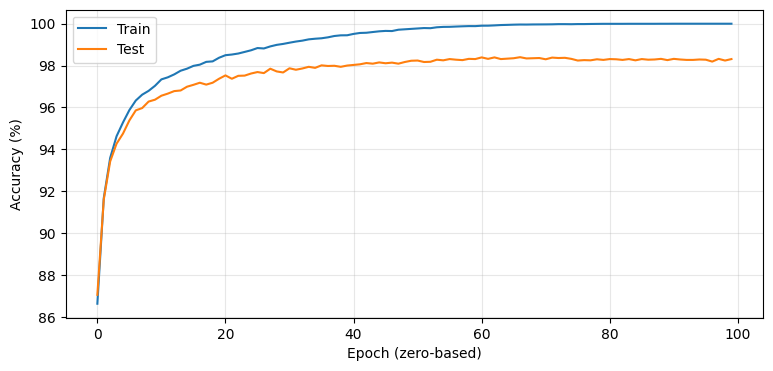

In [6]:
plt.figure(figsize=(9,4))
plt.plot(history['train_acc'], label='Train')
plt.plot(history['test_acc'], label='Test')
plt.xlabel('Epoch (zero-based)')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [8]:
import torch

@torch.no_grad()
def check_per_class(model, loader, device):
    cm = torch.zeros(10, 10, dtype=torch.long)

    for images, labels in loader:
        images = images.to(device).flatten(1)
        logits = model.predict(images)
        preds = logits.argmax(dim=1).cpu()
        labels = labels.cpu()

        cm += torch.bincount(labels * 10 + preds, minlength=100).reshape(10, 10)

    print("Confusion Matrix:")
    print(cm.numpy())

    print("\nPer-Class Accuracy:")
    for i in range(10):
        total = cm[i].sum().item()
        correct = cm[i, i].item()
        print(f"Class {i}: {100 * correct / total:.2f}%")

    print(f"\nOverall Test Accuracy: {100 * cm.diag().sum().item() / cm.sum().item():.2f}%")

check_per_class(model, test_loader, DEVICE)

Confusion Matrix:
[[ 970    0    0    1    1    1    3    2    1    1]
 [   0 1126    3    1    0    1    1    1    2    0]
 [   1    0 1014    2    1    1    2    5    4    2]
 [   0    0    3  993    0    4    0    3    3    4]
 [   0    0    2    1  966    0    4    0    2    7]
 [   2    0    0    6    1  876    2    0    3    2]
 [   3    2    0    1    5    2  944    0    1    0]
 [   0    2    8    0    1    1    0 1007    3    6]
 [   2    1    2    3    4    6    0    3  949    4]
 [   0    2    0    3    7    3    0    6    2  986]]

Per-Class Accuracy:
Class 0: 98.98%
Class 1: 99.21%
Class 2: 98.26%
Class 3: 98.32%
Class 4: 98.37%
Class 5: 98.21%
Class 6: 98.54%
Class 7: 97.96%
Class 8: 97.43%
Class 9: 97.72%

Overall Test Accuracy: 98.31%
